# 🎙️ **DCMC-Fusion — K = 4**

This notebook is part of the article **“DCMC-Fusion: Data-Centric and Model-Centric Ensemble Learning for Audio Deepfake Detection”**, by **Dora Ballesteros and Carlos Guerra**.

Its purpose is to evaluate the performance of four fusion classifiers—Logistic Regression, Random Forest, XGBoost, and SVM—by combining the probabilities generated from four spectral representations (Mel, LOG, DWT, and CQT) of each combination of four architectures. For **K=4**, five datasets are constructed from all possible combinations of four out of the five architectures, resulting in **20 experimental configurations**.



### 📥 Input Files

This experiment requires **three input files**, which must be generated before executing this notebook:

1. **`inference_probabilities.csv`:** generated **prior to and independently of the DCMC-Fusion method**. It contains the inference probabilities produced by 20 previously trained models, corresponding to five architectures (ResNet50, DenseNet121, InceptionV3, ResNet34, and VGG16) and four spectral representations (Mel, LOG, DWT, and CQT). Each row represents an audio sample, and the `label` column contains its ground-truth class (0 = natural, 1 = synthetic).

2. **`best_hyperparameters_k4.json`:** generated by **`Fusion_Classifiers_Hyperparameter_Search_k4.ipynb`**. It contains the optimal hyperparameters selected for each of the four fusion classifiers using five-fold cross-validation and macro F1 as the optimization criterion. These hyperparameters remain fixed across all architecture combinations evaluated for K=4.

3. **`experiment_split.json`:** generated by **`Fusion_Classifiers_Hyperparameter_Search_k4.ipynb`**. It stores the indices of the training and test samples obtained from a stratified 70/30 partition with `random_state=42`, together with information used to verify dataset consistency. The same training–test partition is reused across all values of K.





### 🔬 Experimental Procedure

For **K=4**, five datasets are constructed from all possible combinations of four out of the five architectures. Each dataset contains **16 probability features**, corresponding to four spectral representations per architecture.

Four fusion classifiers—Logistic Regression, Random Forest, XGBoost, and SVM—are evaluated for each architecture combination, resulting in **20 experimental configurations**.

### 📤 Output Files

After executing the notebook, the following CSV files are generated:

1. **`global_metrics_k4.csv`**  
   Contains the global classification metrics (Accuracy, Precision-macro, Recall-macro, and F1-macro) for each architectural combination and fusion classifier.

2. **`class_metrics_k4.csv`**  
   Contains the classification metrics for each class (real and fake), including Precision, Recall, and F1-score.

3. **`fixed_parameters_k4.csv`**  
   Records the hyperparameters used for each fusion classifier.

4. **`timing_metrics_k4.csv`**  
   Contains the individual training and prediction times, in seconds, for each architectural combination and fusion classifier.

5. **`timing_summary_k4.csv`**  
   Summarizes the computational times for each fusion classifier, including the number of architectural combinations, mean training time, standard deviation of training time, mean prediction time, and standard deviation of prediction time.


**Note:** Training times correspond to fitting the fusion classifiers using previously selected hyperparameters, without repeating the hyperparameter optimization process. Prediction times correspond to the complete test partition.

# **1. Dependencies**
Run the installation cell once if the packages are unavailable.

In [1]:
%pip install numpy pandas scikit-learn xgboost ipython --quiet

# **2. Imports**

In [2]:
from pathlib import Path
from itertools import combinations
import json
from time import perf_counter

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

from xgboost import XGBClassifier

# **3. Architecture configuration**

In [3]:
K = 4

ARCHITECTURES = {
    "resnet50": [
        "resnet50_mel", "resnet50_log",
        "resnet50_dwt", "resnet50_cqt"
    ],
    "densenet121": [
        "densenet121_mel", "densenet121_log",
        "densenet121_dwt", "densenet121_cqt"
    ],
    "inception_v3": [
        "inception_v3_mel", "inception_v3_log",
        "inception_v3_dwt", "inception_v3_cqt"
    ],
    "resnet34": [
        "resnet34_mel", "resnet34_log",
        "resnet34_dwt", "resnet34_cqt"
    ],
    "vgg16": [
        "vgg16_mel", "vgg16_log",
        "vgg16_dwt", "vgg16_cqt"
    ]
}

ARCH_ORDER = list(ARCHITECTURES)

FEATURE_COLUMNS = [
    column
    for columns in ARCHITECTURES.values()
    for column in columns
]

CONFIGURATIONS = list(combinations(ARCH_ORDER, K))

# **4. Ensemble dataset preparation**

In [4]:
# Load and validate inference probabilities
CSV_PATH = Path("inference_probabilities.csv")
df = pd.read_csv(CSV_PATH)

required_columns = ["audio", "label"] + FEATURE_COLUMNS
missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

values = df[FEATURE_COLUMNS].to_numpy(dtype=float)

if not np.isfinite(values).all() or ((values < 0) | (values > 100)).any():
    raise ValueError("Probabilities must be finite and in [0, 100].")

if set(df["label"].unique()) != {0, 1}:
    raise ValueError("Labels must contain 0 (natural) and 1 (synthetic).")

y = df["label"].to_numpy(dtype=int)

print(f"Audio samples: {len(df)}")

display(
    df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .to_frame("samples")
)

display(pd.DataFrame({
    "configuration": [" + ".join(c) for c in CONFIGURATIONS],
    "features": [4 * K] * len(CONFIGURATIONS)
}))

Audio samples: 2484


,samples
label,
0,1242
1,1242


,configuration,features
0,resnet50 + densenet121 + inception_v3 + resnet34,16
1,resnet50 + densenet121 + inception_v3 + vgg16,16
2,resnet50 + densenet121 + resnet34 + vgg16,16
3,resnet50 + inception_v3 + resnet34 + vgg16,16
4,densenet121 + inception_v3 + resnet34 + vgg16,16


# **5. Fixed hyperparameters and shared split**

In [5]:
# Load hyperparameters selected in the independent search notebook
with open("best_hyperparameters_k4.json", encoding="utf-8") as file:
    best_hyperparameters = json.load(file)

with open("experiment_split.json", encoding="utf-8") as file:
    split_configuration = json.load(file)

# Verify dataset identity before applying the saved row indices
if df["audio"].astype(str).tolist() != split_configuration["audio_order"]:
    raise ValueError("Audio samples or their order differ from the saved dataset.")

if y.tolist() != split_configuration["label_order"]:
    raise ValueError("Ground-truth labels differ from the saved dataset.")

if FEATURE_COLUMNS != split_configuration["feature_columns"]:
    raise ValueError("Feature columns differ from the search configuration.")

train_indices = np.array(
    split_configuration["train_indices"], dtype=int
)
test_indices = np.array(
    split_configuration["test_indices"], dtype=int
)

# Verify that the split covers every row exactly once
all_indices = np.concatenate([train_indices, test_indices])

if (
    len(train_indices) == 0
    or len(test_indices) == 0
    or not np.array_equal(np.sort(all_indices), np.arange(len(df)))
):
    raise ValueError("The saved split must partition all rows exactly once.")

RANDOM_STATE = split_configuration["random_state"]
np.random.seed(RANDOM_STATE)

print(f"Training samples: {len(train_indices)}")
print(f"Test samples: {len(test_indices)}")

display(pd.DataFrame({
    "training_samples": pd.Series(y[train_indices]).value_counts(),
    "test_samples": pd.Series(y[test_indices]).value_counts()
}).sort_index().rename_axis("label"))

display(pd.DataFrame([
    {
        "classifier": name,
        "fixed_hyperparameters": json.dumps(parameters, sort_keys=True)
    }
    for name, parameters in best_hyperparameters.items()
]))

Training samples: 1738
Test samples: 746


,training_samples,test_samples
label,,
0,869,373
1,869,373


,classifier,fixed_hyperparameters
0,Logistic Regression,"{""C"": 0.1, ""penalty"": ""l2"", ""solver"": ""libline..."
1,Random Forest,"{""max_depth"": 5, ""min_samples_split"": 5, ""n_es..."
2,XGBoost,"{""learning_rate"": 0.01, ""max_depth"": 3, ""n_est..."
3,SVM,"{""C"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf""}"


# **6. Fusion classifiers**

In [6]:
# The selected hyperparameters remain fixed across all configurations
ML_MODELS = {
    "Logistic Regression": LogisticRegression(
        **best_hyperparameters["Logistic Regression"],
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        **best_hyperparameters["Random Forest"],
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        **best_hyperparameters["XGBoost"],
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        verbosity=0,
        n_jobs=-1
    ),

    "SVM": SVC(
        **best_hyperparameters["SVM"],
        probability=True,
        random_state=RANDOM_STATE
    )
}

### Computational cost measurement
Final training and prediction times are measured with `perf_counter()` for every architecture combination and fusion classifier. Training includes preprocessing within the pipeline, but excludes hyperparameter optimization. Results are exported as individual timing records and mean/standard deviation by classifier for this K. Times depend on the runtime hardware and parallelism settings.


# **7. Training and evaluation**

In [7]:
def train_and_evaluate(X_raw, y):
    # Use the same audio samples for every architecture configuration
    X_train = X_raw[train_indices]
    X_test = X_raw[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]

    classifier_results = {}

    for name, classifier in ML_MODELS.items():
        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", clone(classifier))
        ])

        # Fit preprocessing and classifier using only training data
        # Measure final training only; hyperparameter search is excluded
        training_start = perf_counter()
        pipeline.fit(X_train, y_train)
        training_seconds = perf_counter() - training_start

        # Measure predictions on the fixed test partition
        prediction_start = perf_counter()
        y_pred = pipeline.predict(X_test)
        prediction_seconds = perf_counter() - prediction_start

        report = classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["natural", "synthetic"],
            output_dict=True,
            zero_division=0
        )

        classifier_results[name] = {
            "y_test": y_test,
            "y_pred": y_pred,
            "accuracy": accuracy_score(y_test, y_pred),
            "training_seconds": training_seconds,
            "prediction_seconds": prediction_seconds,
            "report": report,
            "fixed_parameters": best_hyperparameters[name].copy(),
            "trained_pipeline": pipeline
        }

    return classifier_results

# **8. Run the five configurations**

In [8]:
# Construct each ensemble dataset and train its four fusion classifiers
results = {}

for selected in CONFIGURATIONS:
    configuration_name = " + ".join(selected)

    columns = [
        column
        for architecture in selected
        for column in ARCHITECTURES[architecture]
    ]

    X_raw = df[columns].to_numpy(dtype=float)

    print(
        f"K={K}: {configuration_name} — {len(columns)} features",
        flush=True
    )

    results[configuration_name] = train_and_evaluate(X_raw, y)

print(
    f"Completed: {len(results)} datasets and "
    f"{len(results) * len(ML_MODELS)} classifier configurations."
)

K=4: resnet50 + densenet121 + inception_v3 + resnet34 — 16 features
K=4: resnet50 + densenet121 + inception_v3 + vgg16 — 16 features
K=4: resnet50 + densenet121 + resnet34 + vgg16 — 16 features
K=4: resnet50 + inception_v3 + resnet34 + vgg16 — 16 features
K=4: densenet121 + inception_v3 + resnet34 + vgg16 — 16 features
Completed: 5 datasets and 20 classifier configurations.


# **9. Results: tables and plots**

In [9]:
global_rows = []
class_rows = []
parameter_rows = []
timing_rows = []

for configuration, classifiers in results.items():
    for classifier, result in classifiers.items():
        base = {
            "K": K,
            "architectures": configuration,
            "classifier": classifier
        }

        timing_rows.append({
            **base,
            "n_features": 4 * K,
            "n_train": len(train_indices),
            "n_test": len(test_indices),
            "training_seconds": result["training_seconds"],
            "prediction_seconds": result["prediction_seconds"]
        })

        macro = result["report"]["macro avg"]

        global_rows.append({
            **base,
            "accuracy": result["accuracy"],
            "precision_macro": macro["precision"],
            "recall_macro": macro["recall"],
            "f1_macro": macro["f1-score"]
        })

        for class_name in ["natural", "synthetic"]:
            metrics = result["report"][class_name]

            class_rows.append({
                **base,
                "class": class_name,
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1-score"],
                "support": int(metrics["support"])
            })

        parameter_rows.append({
            **base,
            "fixed_parameters": json.dumps(
                result["fixed_parameters"],
                sort_keys=True
            )
        })

global_metrics = pd.DataFrame(global_rows)
class_metrics = pd.DataFrame(class_rows)
fixed_parameters = pd.DataFrame(parameter_rows)
timing_metrics = pd.DataFrame(timing_rows)
timing_summary = (
    timing_metrics.groupby(["K", "classifier"], as_index=False)
    .agg(n_combinations=("architectures", "count"),
         mean_training_seconds=("training_seconds", "mean"),
         std_training_seconds=("training_seconds", "std"),
         mean_prediction_seconds=("prediction_seconds", "mean"),
         std_prediction_seconds=("prediction_seconds", "std"))
)

# Metrics are reported on a scale from 0 to 1
print("GLOBAL TEST METRICS")
display(global_metrics)

print("PER-CLASS TEST METRICS")
display(class_metrics)

print("FIXED HYPERPARAMETERS")
display(fixed_parameters)
print("TIMING SUMMARY BY CLASSIFIER AND K (SECONDS)")
display(timing_summary)


GLOBAL TEST METRICS


,K,architectures,classifier,accuracy,precision_macro,recall_macro,f1_macro
0,4,resnet50 + densenet121 + inception_v3 + resnet34,Logistic Regression,0.687668,0.688264,0.687668,0.687420
1,4,resnet50 + densenet121 + inception_v3 + resnet34,Random Forest,0.713137,0.748086,0.713137,0.702665
2,4,resnet50 + densenet121 + inception_v3 + resnet34,XGBoost,0.698391,0.722597,0.698391,0.689963
3,4,resnet50 + densenet121 + inception_v3 + resnet34,SVM,0.701072,0.734595,0.701072,0.689998
4,4,resnet50 + densenet121 + inception_v3 + vgg16,Logistic Regression,0.711796,0.738591,0.711796,0.703471
5,4,resnet50 + densenet121 + inception_v3 + vgg16,Random Forest,0.715818,0.763010,0.715818,0.702471
6,4,resnet50 + densenet121 + inception_v3 + vgg16,XGBoost,0.723861,0.765690,0.723861,0.712547
7,4,resnet50 + densenet121 + inception_v3 + vgg16,SVM,0.717158,0.788006,0.717158,0.698624
8,4,resnet50 + densenet121 + resnet34 + vgg16,Logistic Regression,0.701072,0.725605,0.701072,0.692719
9,4,resnet50 + densenet121 + resnet34 + vgg16,Random Forest,0.722520,0.767534,0.722520,0.710336


PER-CLASS TEST METRICS


,K,architectures,classifier,class,precision,recall,f1,support
0,4,resnet50 + densenet121 + inception_v3 + resnet34,Logistic Regression,natural,0.698864,0.659517,0.678621,373
1,4,resnet50 + densenet121 + inception_v3 + resnet34,Logistic Regression,synthetic,0.677665,0.715818,0.696219,373
2,4,resnet50 + densenet121 + inception_v3 + resnet34,Random Forest,natural,0.841202,0.525469,0.646865,373
3,4,resnet50 + densenet121 + inception_v3 + resnet34,Random Forest,synthetic,0.654971,0.900804,0.758465,373
4,4,resnet50 + densenet121 + inception_v3 + resnet34,XGBoost,natural,0.796000,0.533512,0.638844,373
5,4,resnet50 + densenet121 + inception_v3 + resnet34,XGBoost,synthetic,0.649194,0.863271,0.741082,373
6,4,resnet50 + densenet121 + inception_v3 + resnet34,SVM,natural,0.823276,0.512064,0.631405,373
7,4,resnet50 + densenet121 + inception_v3 + resnet34,SVM,synthetic,0.645914,0.890080,0.748591,373
8,4,resnet50 + densenet121 + inception_v3 + vgg16,Logistic Regression,natural,0.818548,0.544236,0.653784,373
9,4,resnet50 + densenet121 + inception_v3 + vgg16,Logistic Regression,synthetic,0.658635,0.879357,0.753157,373


FIXED HYPERPARAMETERS


,K,architectures,classifier,fixed_parameters
0,4,resnet50 + densenet121 + inception_v3 + resnet34,Logistic Regression,"{""C"": 0.1, ""penalty"": ""l2"", ""solver"": ""libline..."
1,4,resnet50 + densenet121 + inception_v3 + resnet34,Random Forest,"{""max_depth"": 5, ""min_samples_split"": 5, ""n_es..."
2,4,resnet50 + densenet121 + inception_v3 + resnet34,XGBoost,"{""learning_rate"": 0.01, ""max_depth"": 3, ""n_est..."
3,4,resnet50 + densenet121 + inception_v3 + resnet34,SVM,"{""C"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
4,4,resnet50 + densenet121 + inception_v3 + vgg16,Logistic Regression,"{""C"": 0.1, ""penalty"": ""l2"", ""solver"": ""libline..."
5,4,resnet50 + densenet121 + inception_v3 + vgg16,Random Forest,"{""max_depth"": 5, ""min_samples_split"": 5, ""n_es..."
6,4,resnet50 + densenet121 + inception_v3 + vgg16,XGBoost,"{""learning_rate"": 0.01, ""max_depth"": 3, ""n_est..."
7,4,resnet50 + densenet121 + inception_v3 + vgg16,SVM,"{""C"": 0.1, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
8,4,resnet50 + densenet121 + resnet34 + vgg16,Logistic Regression,"{""C"": 0.1, ""penalty"": ""l2"", ""solver"": ""libline..."
9,4,resnet50 + densenet121 + resnet34 + vgg16,Random Forest,"{""max_depth"": 5, ""min_samples_split"": 5, ""n_es..."


TIMING SUMMARY BY CLASSIFIER AND K (SECONDS)


,K,classifier,n_combinations,mean_training_seconds,std_training_seconds,mean_prediction_seconds,std_prediction_seconds
0,4,Logistic Regression,5,0.013529,0.007932,0.002197,0.002051
1,4,Random Forest,5,3.952228,1.284497,0.238695,0.042025
2,4,SVM,5,0.683468,0.337040,0.073828,0.055274
3,4,XGBoost,5,1.266772,1.697478,0.011794,0.010419


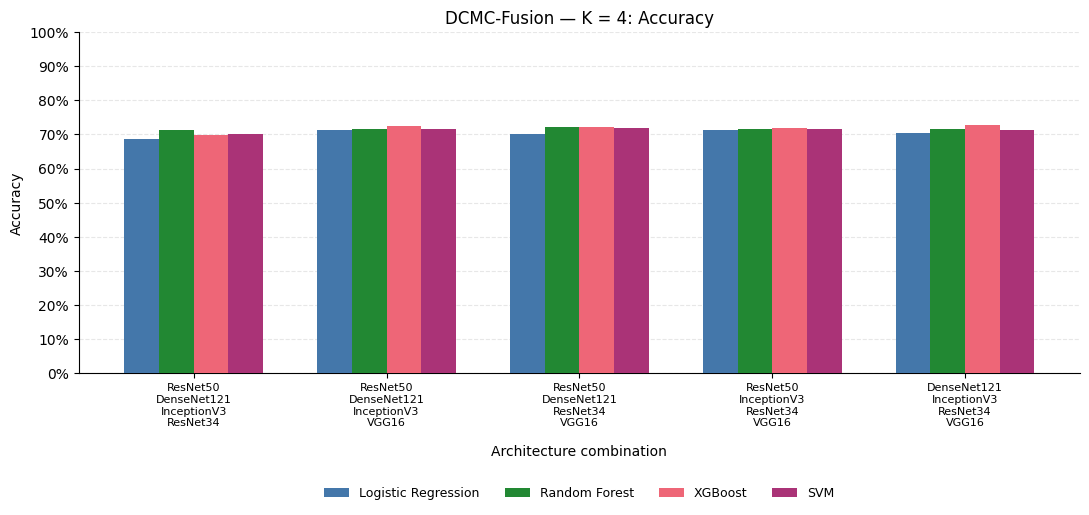

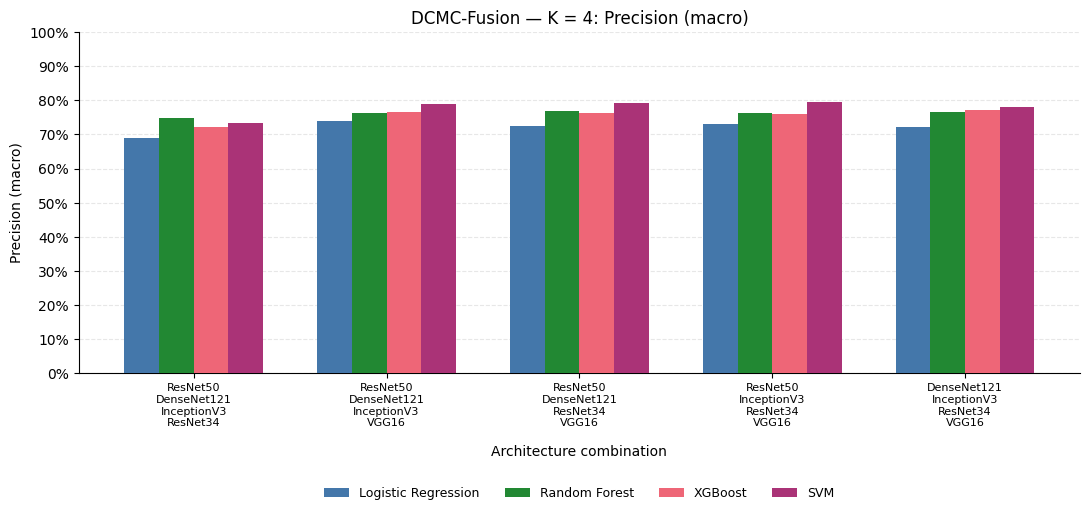

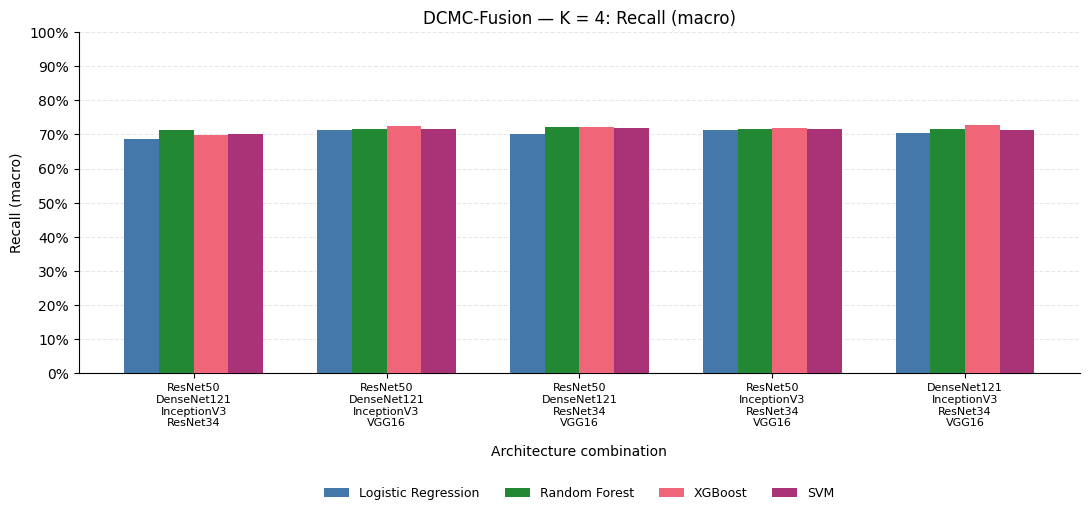

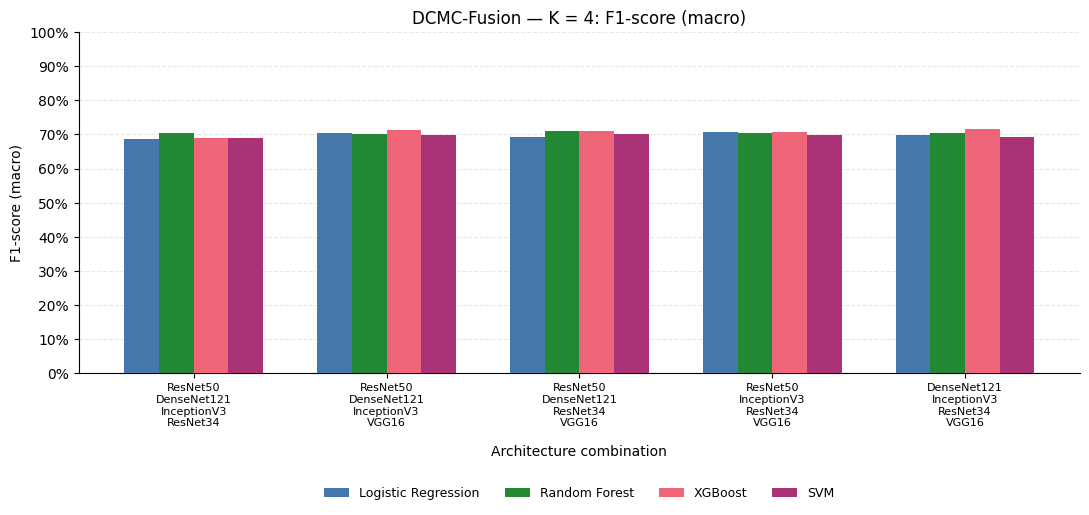

Figures saved to: /content/results/K4/figures


In [10]:
%pip install matplotlib --quiet

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Consistent classifier order and colors across all figures
CLASSIFIER_COLORS = {
    "Logistic Regression": "#4477AA",
    "Random Forest": "#228833",
    "XGBoost": "#EE6677",
    "SVM": "#AA3377"
}

ARCHITECTURE_LABELS = {
    "resnet50": "ResNet50",
    "densenet121": "DenseNet121",
    "inception_v3": "InceptionV3",
    "resnet34": "ResNet34",
    "vgg16": "VGG16"
}

METRICS = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1-score (macro)"
}

FIGURE_DIR = Path("results") / f"K{K}" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

configuration_order = [
    " + ".join(selected)
    for selected in CONFIGURATIONS
]

# Display each architecture on a separate line
architecture_labels = [
    "\n".join(ARCHITECTURE_LABELS[arch] for arch in selected)
    for selected in CONFIGURATIONS
]

classifier_order = list(CLASSIFIER_COLORS)
x = np.arange(len(configuration_order))
bar_width = 0.18

for metric, metric_label in METRICS.items():
    metric_table = (
        global_metrics
        .pivot(
            index="architectures",
            columns="classifier",
            values=metric
        )
        .reindex(
            index=configuration_order,
            columns=classifier_order
        )
    )

    if metric_table.isna().any().any():
        raise ValueError(f"Missing results for {metric_label}.")

    fig, ax = plt.subplots(figsize=(11, 5.5))

    for i, classifier in enumerate(classifier_order):
        offset = (i - (len(classifier_order) - 1) / 2) * bar_width

        ax.bar(
            x + offset,
            metric_table[classifier].to_numpy() * 100,
            width=bar_width,
            color=CLASSIFIER_COLORS[classifier],
            label=classifier,
            zorder=3
        )

    ax.set_title(f"DCMC-Fusion — K = {K}: {metric_label}")

    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25),ncol=4,frameon=False,fontsize=9)

    ax.set_ylabel(metric_label)

    ax.set_xticks(x)

    ax.set_ylim(0, 100)
    ax.set_yticks(np.arange(0, 101, 10))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

    ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_xticklabels(architecture_labels, fontsize=8)
    ax.set_xlabel("Architecture combination", fontsize=10, labelpad=12)

    ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.30),
    ncol=4,
    frameon=False,
    fontsize=9)

    fig.tight_layout()

    for extension in ["png", "pdf"]:
        fig.savefig(
            FIGURE_DIR / f"K{K}_{metric}.{extension}",
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    plt.close(fig)

print(f"Figures saved to: {FIGURE_DIR.resolve()}")

# **10. Export results**

In [11]:
OUTPUT_DIR = Path("results") / f"K{K}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

global_metrics.to_csv(
    OUTPUT_DIR / "global_metrics_k4.csv",
    index=False
)

class_metrics.to_csv(
    OUTPUT_DIR / "class_metrics_k4.csv",
    index=False
)

fixed_parameters.to_csv(
    OUTPUT_DIR / "fixed_parameters_k4.csv",
    index=False
)

print(f"Results saved to: {OUTPUT_DIR.resolve()}")
# Export individual timings and averages for this K
timing_metrics.to_csv(
    OUTPUT_DIR / "timing_metrics_k4.csv", index=False
)
timing_summary.to_csv(
    OUTPUT_DIR / "timing_summary_k4.csv", index=False
)


Results saved to: /content/results/K4
